# Instagram Creator Analytics: Data Understanding, Cleaning & EDA

This notebook loads the raw Instagram post dataset, validates it, creates the analysis columns (`total_engagement`, `engagement_rate_calc`), saves the cleaned file to `Data/Cleaned/instagram_creator_cleaned.csv`, and then explores performance by media type, content category, posting time, traffic source, CTA and follower growth.

Run the cells top to bottom from the `Python/` folder.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the raw data

In [2]:
df = pd.read_csv("../Data/Raw/Dataset A.csv")
df.head()

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,post_hour,day_of_week,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,6,Saturday,194,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,15,Friday,449,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,16,Thursday,114,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,3,Thursday,91,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,9,Friday,154,8,5,21,5350,8503,0.0221,155,112,9,low


In [3]:
df.shape

(29999, 23)

In [4]:
df.columns

Index(['post_id', 'account_id', 'account_type', 'follower_count', 'media_type',
       'content_category', 'traffic_source', 'has_call_to_action',
       'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes',
       'comments', 'shares', 'saves', 'reach', 'impressions',
       'engagement_rate', 'followers_gained', 'caption_length',
       'hashtags_count', 'performance_bucket_label'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  str    
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  str    
 3   follower_count            29999 non-null  int64  
 4   media_type                29999 non-null  str    
 5   content_category          29999 non-null  str    
 6   traffic_source            29999 non-null  str    
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  str    
 9   post_date                 29999 non-null  str    
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  str    
 12  likes                     29999 non-null  int64  
 13  comments                  29999 non-null  int64  
 14  shares           

In [6]:
df.describe()

,account_id,follower_count,has_call_to_action,post_hour,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count
count,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000,29999.000000
mean,10.567819,10278.305477,0.348778,11.499417,287.653588,8.521917,14.426614,42.517284,6272.475449,8466.952498,0.042107,502.152805,120.081169,7.987933
std,5.763952,6691.862669,0.476592,6.900587,317.647682,10.116505,16.420899,47.808844,4985.877059,6825.900355,0.024095,290.364038,11.009108,2.828130
min,1.000000,3083.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,268.000000,327.000000,0.000000,0.000000,70.000000,0.000000
25%,6.000000,5824.000000,0.000000,6.000000,104.000000,3.000000,5.000000,15.000000,3058.000000,4102.000000,0.024000,251.000000,113.000000,6.000000
50%,11.000000,9044.000000,0.000000,12.000000,199.000000,6.000000,10.000000,29.000000,4913.000000,6595.000000,0.040600,501.000000,120.000000,8.000000
75%,16.000000,10739.000000,1.000000,17.000000,363.000000,11.000000,19.000000,54.000000,7863.000000,10620.500000,0.057000,755.000000,127.000000,10.000000
max,20.000000,31095.000000,1.000000,23.000000,10632.000000,339.000000,516.000000,1542.000000,73339.000000,105203.000000,0.271000,1000.000000,166.000000,21.000000


## 3. Data quality checks

Missing values, duplicate rows, duplicate post IDs and negative values in count columns.

In [7]:
df.isnull().sum()

post_id                     0
account_id                  0
account_type                0
follower_count              0
media_type                  0
content_category            0
traffic_source              0
has_call_to_action          0
post_datetime               0
post_date                   0
post_hour                   0
day_of_week                 0
likes                       0
comments                    0
shares                      0
saves                       0
reach                       0
impressions                 0
engagement_rate             0
followers_gained            0
caption_length              0
hashtags_count              0
performance_bucket_label    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["post_id"].duplicated().sum()

np.int64(0)

In [10]:
numeric_cols = ["follower_count","likes","comments","shares","saves","reach","impressions","followers_gained","caption_length","hashtags_count"]
(df[numeric_cols]<0).sum()

follower_count      0
likes               0
comments            0
shares              0
saves               0
reach               0
impressions         0
followers_gained    0
caption_length      0
hashtags_count      0
dtype: int64

Categorical columns: check the values are clean and consistent.

In [11]:
print("Account Types:")
print(df["account_type"].value_counts())

print("Media Types:")
print(df["media_type"].value_counts())

print("Content Categories:")
print(df["content_category"].value_counts())

print("Traffic Sources:")
print(df["traffic_source"].value_counts())

print("Performance Bucket:")
print(df["performance_bucket_label"].value_counts())

Account Types:
account_type
creator    20944
brand       9055
Name: count, dtype: int64
Media Types:
media_type
image       11927
carousel    10627
reel         7445
Name: count, dtype: int64
Content Categories:
content_category
Photography    3035
Fashion        3034
Technology     3025
Lifestyle      3017
Food           3010
Fitness        3004
Music          3003
Travel         2968
Beauty         2953
Comedy         2950
Name: count, dtype: int64
Traffic Sources:
traffic_source
Home Feed     5069
Hashtags      5063
Reels Feed    5026
External      5005
Profile       4962
Explore       4874
Name: count, dtype: int64
Performance Bucket:
performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64


In [12]:
df["has_call_to_action"].value_counts()

has_call_to_action
0    19536
1    10463
Name: count, dtype: int64

In [13]:
print(df["post_date"].head())
print(df["post_datetime"].head())

0    2024-11-30
1    2025-08-15
2    2025-09-11
3    2025-09-18
4    2025-03-21
Name: post_date, dtype: str
0    2024-11-30 06:00:00
1    2025-08-15 15:00:00
2    2025-09-11 16:00:00
3    2025-09-18 03:00:00
4    2025-03-21 09:00:00
Name: post_datetime, dtype: str


## 4. Data cleaning

Work on a copy, standardise column names, and parse the date columns.

In [14]:
df_clean = df.copy()

df_clean.columns = (df_clean.columns
                    .str.strip()
                    .str.lower()
                    .str.replace(" ","_"))

In [15]:
df_clean.columns

Index(['post_id', 'account_id', 'account_type', 'follower_count', 'media_type',
       'content_category', 'traffic_source', 'has_call_to_action',
       'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes',
       'comments', 'shares', 'saves', 'reach', 'impressions',
       'engagement_rate', 'followers_gained', 'caption_length',
       'hashtags_count', 'performance_bucket_label'],
      dtype='str')

In [16]:
df_clean["post_date"] = pd.to_datetime(df_clean["post_date"],errors="coerce")
df_clean["post_datetime"] = pd.to_datetime(df_clean["post_datetime"],errors="coerce")

In [17]:
df_clean[["post_date","post_datetime"]].dtypes

post_date        datetime64[us]
post_datetime    datetime64[us]
dtype: object

In [18]:
df_clean[["post_date","post_datetime"]].isnull().sum()

post_date        0
post_datetime    0
dtype: int64

## 5. Derived metrics

- `total_engagement` = likes + comments + shares + saves
- `engagement_rate_calc` = total_engagement / reach × 100

In [19]:
df_clean["total_engagement"] = df_clean["likes"] + df_clean["comments"] + df_clean["shares"] + df_clean["saves"]
df_clean[["likes","comments","shares","saves","total_engagement"]].head()

,likes,comments,shares,saves,total_engagement
0,194,5,7,34,240
1,449,10,21,68,548
2,114,2,1,22,139
3,91,0,7,0,98
4,154,8,5,21,188


In [20]:
df_clean["engagement_rate_calc"] = (df_clean["total_engagement"] / df_clean["reach"]) * 100
df_clean[["total_engagement","engagement_rate","engagement_rate_calc"]].head(10)

,total_engagement,engagement_rate,engagement_rate_calc
0,240,0.0385,5.546568
1,548,0.0663,7.354717
2,139,0.0531,8.480781
3,98,0.0309,3.406326
4,188,0.0221,3.514019
5,179,0.0516,6.709145
6,448,0.0584,8.927860
7,22,0.0162,2.040816
8,160,0.0657,8.421053
9,118,0.0401,5.475638


Compare the calculated rate with the source `engagement_rate` column. The source column is a fraction on a different basis, so the calculated rate is used for all analysis.

In [21]:
difference = df_clean["engagement_rate_calc"] - df_clean["engagement_rate"]
difference.describe()

count    29999.000000
mean         5.574602
std          3.104903
min          0.000000
25%          3.222784
50%          5.426729
75%          7.642539
max         29.871141
dtype: float64

## 6. Save the cleaned dataset

In [22]:
print(df_clean.shape)
df_clean.to_csv("../Data/Cleaned/instagram_creator_cleaned.csv", index=False)

(29999, 25)


# Exploratory Data Analysis

## 7. Overall KPIs

In [23]:
kpis = {
    "Total Posts": len(df_clean),
    "Total Engagement": df_clean["total_engagement"].sum(),
    "Average Engagement": df_clean["total_engagement"].mean(),
    "Average Reach": df_clean["reach"].mean(),
    "Average Impressions": df_clean["impressions"].mean(),
    "Average Engagement Rate": df_clean["engagement_rate_calc"].mean(),
    "Total Followers Gained": df_clean["followers_gained"].sum()
}

pd.Series(kpis).round(2)

Total Posts                   29999.00
Total Engagement           10593229.00
Average Engagement              353.12
Average Reach                  6272.48
Average Impressions            8466.95
Average Engagement Rate           5.62
Total Followers Gained     15064082.00
dtype: float64

## 8. Engagement distribution

In [24]:
df_clean["total_engagement"].describe().round(2)

count    29999.00
mean       353.12
std        388.13
min          0.00
25%        128.00
50%        243.00
75%        444.00
max      13029.00
Name: total_engagement, dtype: float64

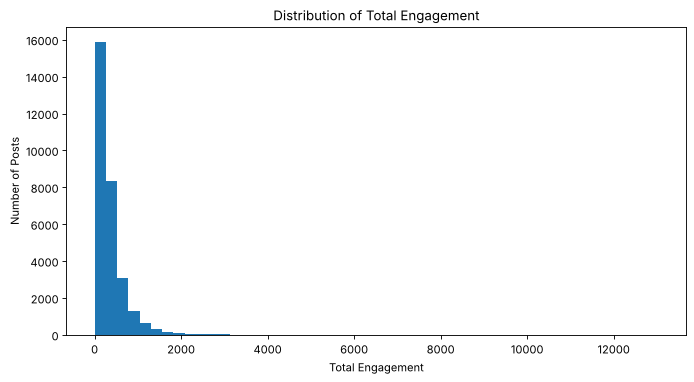

In [25]:
plt.figure(figsize=(10, 5))

plt.hist(df_clean["total_engagement"], bins=50)

plt.title("Distribution of Total Engagement")
plt.xlabel("Total Engagement")
plt.ylabel("Number of Posts")

plt.show()

## 9. Media type analysis

In [26]:
media_analysis = (
    df_clean.groupby("media_type")
    .agg(
        posts=("post_id", "count"),
        avg_engagement=("total_engagement", "mean"),
        avg_reach=("reach", "mean"),
        avg_engagement_rate=("engagement_rate_calc", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

media_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
media_type,,,,
image,11927,355.53,6268.62,5.64
carousel,10627,351.86,6329.10,5.57
reel,7445,351.06,6197.83,5.64


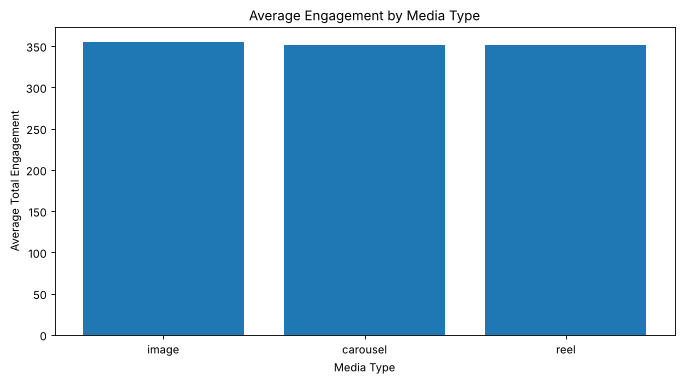

In [27]:
plt.figure(figsize=(10, 5))

plt.bar(
    media_analysis.index,
    media_analysis["avg_engagement"]
)

plt.title("Average Engagement by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Average Total Engagement")

plt.show()

## 10. Content category analysis

In [28]:
category_analysis = (
    df_clean.groupby("content_category")
    .agg(
        posts=("post_id", "count"),
        avg_engagement=("total_engagement", "mean"),
        avg_reach=("reach", "mean"),
        avg_engagement_rate=("engagement_rate_calc", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

category_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
content_category,,,,
Fashion,3034,363.92,6347.16,5.69
Music,3003,358.46,6274.30,5.71
Photography,3035,356.43,6417.29,5.53
Comedy,2950,355.18,6303.41,5.58
Fitness,3004,354.66,6218.89,5.67
Beauty,2953,354.50,6340.98,5.62
Food,3010,353.43,6248.64,5.61
Lifestyle,3017,350.50,6261.53,5.58
Travel,2968,343.22,6220.46,5.57


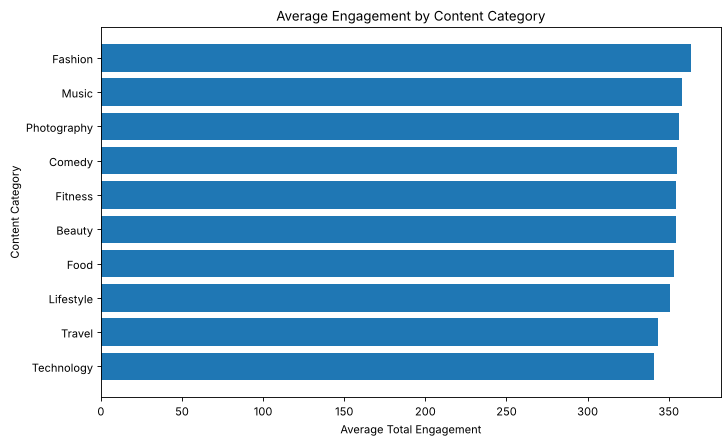

In [29]:
plt.figure(figsize=(10, 6))

plt.barh(
    category_analysis.index[::-1],
    category_analysis["avg_engagement"][::-1]
)

plt.title("Average Engagement by Content Category")
plt.xlabel("Average Total Engagement")
plt.ylabel("Content Category")

plt.show()

## 11. Posting time analysis

In [30]:
hour_analysis = (
    df_clean.groupby("post_hour")
    .agg(
        posts=("post_id", "count"),
        avg_engagement=("total_engagement", "mean"),
        avg_reach=("reach", "mean"),
        avg_engagement_rate=("engagement_rate_calc", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

hour_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
post_hour,,,,
3,1256,392.19,6519.89,5.80
21,1199,373.01,6560.73,5.63
2,1195,370.64,6274.36,5.77
8,1242,369.67,6310.38,5.78
17,1242,366.65,6460.04,5.69
18,1235,365.75,6532.61,5.63
11,1283,360.84,6402.38,5.61
16,1210,355.08,6340.31,5.62
19,1254,354.45,6352.21,5.53


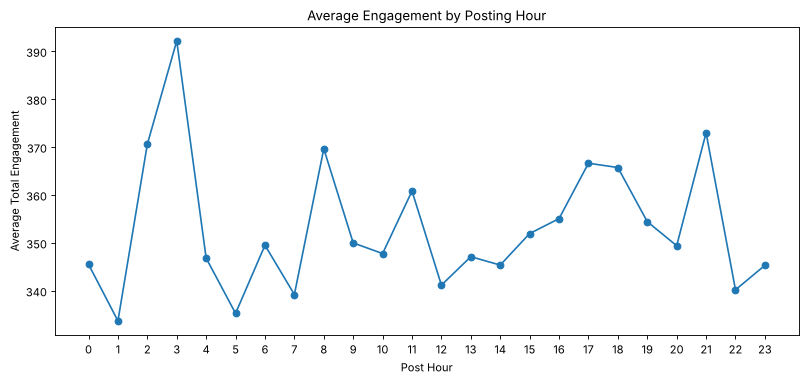

In [31]:
hour_chart = (
    df_clean.groupby("post_hour")["total_engagement"]
    .mean()
    .reset_index()
    .sort_values("post_hour")
)

plt.figure(figsize=(12, 5))

plt.plot(
    hour_chart["post_hour"],
    hour_chart["total_engagement"],
    marker = "o"
)

plt.title("Average Engagement by Posting Hour")
plt.xlabel("Post Hour")
plt.ylabel("Average Total Engagement")
plt.xticks(range(24))

plt.show()

In [32]:
day_analysis = (
    df_clean.groupby("day_of_week")
    .agg(
        posts=("post_id", "count"),
        avg_engagement=("total_engagement", "mean"),
        avg_reach=("reach", "mean"),
        avg_engagement_rate=("engagement_rate_calc", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

day_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
day_of_week,,,,
Sunday,4205,362.31,6366.95,5.66
Tuesday,4351,360.57,6298.74,5.68
Friday,4218,356.99,6283.44,5.64
Monday,4279,355.55,6385.70,5.55
Thursday,4351,348.98,6269.07,5.59
Wednesday,4341,344.32,6169.06,5.57
Saturday,4254,343.35,6136.49,5.62


## 12. Traffic source analysis

In [33]:
traffic_analysis = (
    df_clean.groupby("traffic_source")
    .agg(
        posts=("post_id", "count"),
        avg_engagement=("total_engagement", "mean"),
        avg_reach=("reach", "mean"),
        avg_engagement_rate=("engagement_rate_calc", "mean")
    )
    .sort_values("avg_engagement", ascending=False)
)

traffic_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
traffic_source,,,,
External,5005,362.17,6381.32,5.63
Profile,4962,358.08,6221.92,5.67
Reels Feed,5026,355.04,6299.96,5.66
Hashtags,5063,351.50,6330.00,5.59
Explore,4874,348.74,6207.25,5.60
Home Feed,5069,343.25,6192.50,5.54


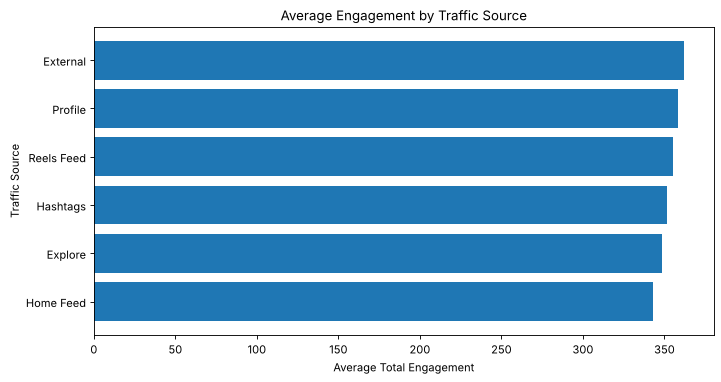

In [34]:
plt.figure(figsize=(10, 5))

plt.barh(
    traffic_analysis.index[::-1],
    traffic_analysis["avg_engagement"][::-1]
)

plt.title("Average Engagement by Traffic Source")
plt.xlabel("Average Total Engagement")
plt.ylabel("Traffic Source")

plt.show()

## 13. Call-to-action (CTA) analysis

In [35]:
cta_analysis = df_clean.groupby("has_call_to_action").agg(
    posts = ("post_id","count"),
    avg_engagement = ("total_engagement","mean"),
    avg_reach = ("reach","mean"),
    avg_engagement_rate = ("engagement_rate_calc","mean")
).sort_values("avg_engagement",ascending=False)

cta_analysis.round(2)

,posts,avg_engagement,avg_reach,avg_engagement_rate
has_call_to_action,,,,
0,19536,353.68,6250.41,5.63
1,10463,352.08,6313.68,5.60


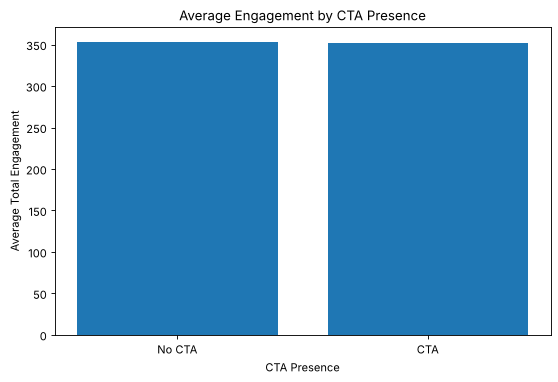

In [36]:
cta_chart = cta_analysis.copy()

cta_chart.index = cta_chart.index.map({0: "No CTA", 1: "CTA"})

plt.figure(figsize=(8, 5))

plt.bar(
    cta_chart.index,
    cta_chart["avg_engagement"]
)

plt.title("Average Engagement by CTA Presence")
plt.xlabel("CTA Presence")
plt.ylabel("Average Total Engagement")

plt.show()

## 14. Audience growth analysis

In [37]:
df_clean["followers_gained"].describe().round(2)

count    29999.00
mean       502.15
std        290.36
min          0.00
25%        251.00
50%        501.00
75%        755.00
max       1000.00
Name: followers_gained, dtype: float64

In [38]:
category_growth = (
    df_clean.groupby("content_category")
    .agg(
        posts=("post_id", "count"),
        avg_followers_gained=("followers_gained", "mean"),
        total_followers_gained=("followers_gained", "sum")
    )
    .sort_values("avg_followers_gained", ascending=False)
)

category_growth.round(2)

,posts,avg_followers_gained,total_followers_gained
content_category,,,
Music,3003,512.87,1540160
Lifestyle,3017,508.99,1535630
Beauty,2953,505.48,1492681
Photography,3035,503.24,1527338
Food,3010,503.05,1514179
Travel,2968,503.03,1493002
Comedy,2950,498.47,1470488
Fashion,3034,497.58,1509648
Fitness,3004,497.25,1493739


In [39]:
media_growth = (
    df_clean.groupby("media_type")
    .agg(
        posts=("post_id", "count"),
        avg_followers_gained=("followers_gained", "mean"),
        total_followers_gained=("followers_gained", "sum")
    )
    .sort_values("avg_followers_gained", ascending=False)
)

media_growth.round(2)

,posts,avg_followers_gained,total_followers_gained
media_type,,,
carousel,10627,506.86,5386412
image,11927,500.91,5974405
reel,7445,497.42,3703265


In [40]:
df_clean[["total_engagement", "followers_gained"]].corr().round(3)

,total_engagement,followers_gained
total_engagement,1.000,-0.005
followers_gained,-0.005,1.000


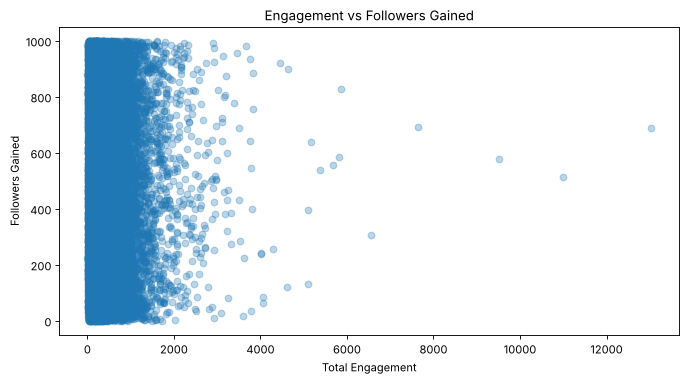

In [41]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_clean["total_engagement"],
    df_clean["followers_gained"],
    alpha=0.3
)

plt.title("Engagement vs Followers Gained")
plt.xlabel("Total Engagement")
plt.ylabel("Followers Gained")

plt.show()

## 15. Relationship analysis

In [42]:
correlation_data = df_clean[
    [
        "likes",
        "comments",
        "shares",
        "saves",
        "reach",
        "impressions",
        "total_engagement",
        "followers_gained"
    ]
].corr().round(3)

correlation_data

,likes,comments,shares,saves,reach,impressions,total_engagement,followers_gained
likes,1.000,0.910,0.945,0.948,0.738,0.723,0.999,-0.005
comments,0.910,1.000,0.886,0.886,0.690,0.674,0.917,-0.006
shares,0.945,0.886,1.000,0.921,0.716,0.700,0.952,-0.003
saves,0.948,0.886,0.921,1.000,0.722,0.707,0.961,-0.003
reach,0.738,0.690,0.716,0.722,1.000,0.986,0.742,-0.005
impressions,0.723,0.674,0.700,0.707,0.986,1.000,0.726,-0.006
total_engagement,0.999,0.917,0.952,0.961,0.742,0.726,1.000,-0.005
followers_gained,-0.005,-0.006,-0.003,-0.003,-0.005,-0.006,-0.005,1.000


## 16. Insights

### Overall Performance:
- The dataset contains 29,999 posts with 10.59M total engagements.
- Average engagement per post is 353.12.
- Average reach per post is 6,272.48.
- Average engagement rate is 5.62%.
- Total followers gained across all posts is 15.06M.

### Engagement:
- Total engagement is strongly right-skewed, with most posts having relatively low engagement and a small number of highly engaged posts.
- The median engagement (243) is considerably lower than the mean (353.12), showing the effect of high-performing posts.

### Media Type:
- Image posts have the highest average engagement (355.53).
- Media types perform similarly overall, with only small differences in engagement, reach, and engagement rate.

### Content Category:
- Fashion has the highest average engagement (363.92).
- Photography has the highest average reach (6,417.29).
- Music has the highest average engagement rate (5.71%).
- Music also has the highest average follower growth (512.87 per post).

### Posting Time:
- 3 AM has the highest average engagement by posting hour (392.19).
- Sunday has the highest average engagement by day (362.31).
- Posting-time performance is irregular, so the data does not indicate one universally optimal posting time.

### Traffic Source:
- External traffic has the highest average engagement (362.17) and reach (6,381.32).
- Profile traffic has the highest average engagement rate (5.67%).
- Differences between traffic sources are moderate.

### CTA:
- Posts with and without CTAs have very similar average engagement.
- CTA presence does not appear to be a major differentiator of average post performance in this dataset.

### Audience Growth:
- Average followers gained per post is 502.15.
- Carousel posts have the highest average follower growth among media types (506.86).
- Total engagement and followers gained have almost no linear relationship (correlation = -0.005).

### Relationships:
- Reach and impressions have a very strong positive correlation (0.986).
- Engagement is positively related to reach and impressions.
- Follower growth has almost no linear correlation with the analyzed performance metrics.